Tugas Mechine Learning 12

12.1 Persiapan Library

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

12.2 Import Dataset

In [34]:
digits = load_digits()
X, y = digits.data, digits.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

12.3 Preprocessing

In [35]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

12.4 Training Model (Keras Sequential API)

In [36]:
model = keras.Sequential([
    keras.layers.Dense(64, activation="relu", input_shape=(X_train.shape[1],)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(10, activation="softmax")]) # 10 kelas angka (0-9)

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

history = model.fit(X_train, y_train, validation_split=0.2, epochs=50, batch_size=32, verbose=0)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12.5 Evaluasi

In [37]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Akurasi Test : {test_acc:.3f}")

Akurasi Test : 0.978


12.6 Visualisasi

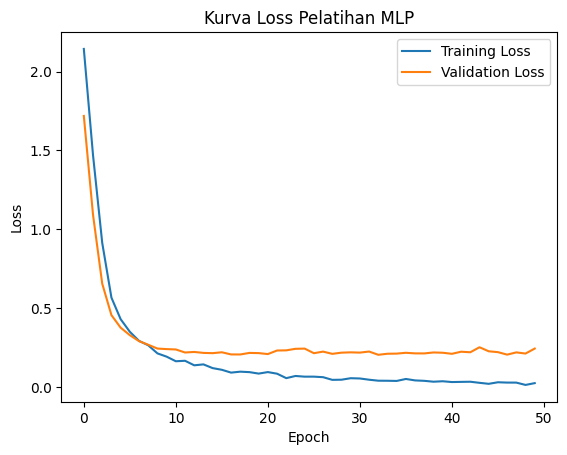

In [38]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label = "Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Kurva Loss Pelatihan MLP")
plt.legend()
plt.show()

12.7 Praktikum 1

In [39]:
arsitektur_list = [ [32], [64,32], [128,64,32] ]
for arsitektur in arsitektur_list:
  layers = [keras.layers.Dense(n,activation="relu") for n in arsitektur]
  model = keras.Sequential([keras.layers.Input(shape=(X_train.shape[1],))] + layers + [keras.layers.Dense(10,activation="softmax")])
  model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
  history = model.fit(X_train,y_train,validation_split=0.2,epochs=30,verbose=0)
  print(f"Arsitektur {arsitektur}: val_accuracy akhir = {history.history['val_accuracy'][-1]:.3f}")

Arsitektur [32]: val_accuracy akhir = 0.944
Arsitektur [64, 32]: val_accuracy akhir = 0.948
Arsitektur [128, 64, 32]: val_accuracy akhir = 0.951


12.8 Praktikum 2

In [40]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
history = model.fit(X_train, y_train, validation_split=0.2, epochs=100, callbacks=[early_stop], verbose=0)
print("Pelatihan berhenti pada epoch:", len(history.history["loss"]))

Pelatihan berhenti pada epoch: 6
